# 12 · Real openCOSMO-RS binary and ternary SLLE

**Real-mixture calculation.** Run top to bottom. Model parameters and pure-component data are identified explicitly. These are model predictions, not a fit or an experimental validation of SLLE. See the [course index](../tutorials.md).

<a class="md-button" href="12_binary_ternary_slle_cosmors.ipynb" download>Download notebook</a>


This notebook **executes the compiled openCOSMO-RS model** on actual Turbomole
conformers. It computes both binary benzene/water flashes and ternary
benzene/water/ethanol S+L₁+L₂ equilibrium. No surrogate or synthetic activity model
is substituted. The committed output was produced with real COSMO inputs;
a new execution requires the same kind of external data.

Set `THERMOWEAVE_COSMO_ROOT` to the COSMOconf25 `NeutralSpecies` directory and
make the compiled `openCOSMORS` module importable (or set
`THERMOWEAVE_OPENCOSMORS_BUILD` to its build directory). The helper resolves
`C6H6_001_benzene`, `H2O` and `C2H6O_001_ethanol`, each at `COSMO_TZVPD_FINE`.
The parametrization defaults to the engine's **default_turbomole**;
`THERMOWEAVE_COSMO_PARAMETERS` explicitly selects another compatible set.
Conformer filenames/hashes and parameter identity are printed for provenance.
Files and weights are not downloaded or bundled.

See the [portable setup guide](../models/opencosmors.md) for backend installation,
OS differences, database paths, parametrizations and a short verification command.

In [1]:
import hashlib, json, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import build_cosmors_model, load_parametrization
from thermoweave.equilibrium.reduced_held import ReducedChart, ReducedHELD, Solid
from _support import COMPONENTS, cosmo_components, solid_gibbs, held_settings, check_flash, phase_table, phase_label, ternary_plot
names = ['benzene', 'water', 'ethanol']
definitions, manifest = cosmo_components(names)
parameter_source = os.environ.get('THERMOWEAVE_COSMO_PARAMETERS', 'default_turbomole')
parametrization = load_parametrization(parameter_source)
identity = {k:v for k,v in parametrization.to_dict().items() if k != 'source'}
print('Parametrization:', Path(parameter_source).name)
print('Parameter-content SHA256:', hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest())
print('Actual conformer manifest:', json.dumps(manifest,indent=2))
settings = held_settings(noisy=True)  # float backend: finite differences above model noise
print(settings)

Parametrization: default_turbomole
Parameter-content SHA256: 4053ef017418f317c99a8527e6e5b9911297e33efe419744ec9431d4a5bb63eb
Actual conformer manifest: [
  {
    "name": "benzene",
    "basis": "COSMO_TZVPD_FINE",
    "conformers": [
      {
        "file": "C6H6_001_benzene_CnfS1_c000.cosmo",
        "sha256": "3114b29eadf951907d29a6c16888952ce99a1f3af6a210074fd972868d76d4fc"
      }
    ]
  },
  {
    "name": "water",
    "basis": "COSMO_TZVPD_FINE",
    "conformers": [
      {
        "file": "H2O_c000.cosmo",
        "sha256": "2d46cfea8920ed3770e91a4cf3dcc4720205e8b6483d4be834b832a0da6df44a"
      }
    ]
  },
  {
    "name": "ethanol",
    "basis": "COSMO_TZVPD_FINE",
    "conformers": [
      {
        "file": "C2H6O_001_ethanol_CnfS1_c000.cosmo",
        "sha256": "4c848f182351b681256edf70c609ef51f643b99c52ff5ad45ee53b9ebab333ce"
      },
      {
        "file": "C2H6O_001_ethanol_CnfS1_c001.cosmo",
        "sha256": "121a8e463a3d1b9e32cdea31309026106708960f948489d821b7b228146

## Binary: benzene + water
Use the real model adapter in the same `ReducedHELD` API as notebook 10.
At 275 K the feed contains a saturated aqueous liquid and benzene(s); at 279 K
it contains two liquids for this parametrization. Fusion data and the solid
pure-liquid gauge are unchanged from the SAFT calculation.

In [2]:
binary_names = names[:2]
binary_model = build_cosmors_model(parametrization, definitions[:2])
binary_chart = ReducedChart.build([0.,0.], [COMPONENTS[n]['molar_mass_g_mol'] for n in binary_names])
for T in [275., 279.]:
    solid = Solid('benzene(s)', [1.,0.], solid_gibbs(T))
    out = ReducedHELD(binary_model, T, binary_chart, settings, solids=[solid]).flash([.5,.5])
    print('Binary T [K]:', T, '; assemblage:', phase_label(out))
    print(phase_table(out,binary_names))
    print(check_flash(binary_model,T,[.5,.5],out,tol=5e-5))


BINARY SPECS
-------------------------
 compile mode: RELEASE
       openmp: activated
vectorization: AVX
-------------------------

loadMolecules for every molecule worked...


Binary T [K]: 275.0 ; assemblage: S+L
[{'phase': 'liquid', 'mole_fraction_of_total': 0.5001385316423111, 'mass_fraction_of_total': 0.1876362198009498, 'x_benzene': 0.0002769865382934042, 'x_water': 0.9997230134617064}, {'phase': 'benzene(s)', 'mole_fraction_of_total': 0.4998614683576888, 'mass_fraction_of_total': 0.8123637801990503, 'x_benzene': 1.0, 'x_water': 0.0}]
{'species_balance_error_mol': 2.2407631306009534e-12, 'liquid_mu_error_over_RT': 0.0, 'solid_saturation_error_over_RT': np.float64(2.087156441427096e-08), 'gibbs_reconstruction_error_over_RT': np.float64(1.1449174941446927e-16), 'phase_mole_fractions': [0.5001385316418347, 0.4998614683572126], 'phase_mass_fractions': [0.1876362198009498, 0.8123637801990503]}


Binary T [K]: 279.0 ; assemblage: L1+L2
[{'phase': 'liquid', 'mole_fraction_of_total': 0.4998817339074455, 'mass_fraction_of_total': 0.8123478390520092, 'x_benzene': 0.9999218017207405, 'x_water': 7.819827925951799e-05}, {'phase': 'liquid', 'mole_fraction_of_total': 0.5001182660925545, 'mass_fraction_of_total': 0.18765216094799086, 'x_benzene': 0.0003146375460519196, 'x_water': 0.999685362453948}]
{'species_balance_error_mol': 2.220446049250313e-16, 'liquid_mu_error_over_RT': 2.4248317112909867e-15, 'solid_saturation_error_over_RT': 0.0, 'gibbs_reconstruction_error_over_RT': np.float64(5.421010862427522e-20), 'phase_mole_fractions': [0.4998817339074455, 0.5001182660925545], 'phase_mass_fractions': [0.8123478390520092, 0.18765216094799086]}


## Binary S+L1+L2 invariant with the actual COSMO-RS model
As in notebook 10, locate the temperature where the two liquid chemical
potentials also equal benzene(s). Three phase amounts are non-unique in this
binary invariant; compare chemical potentials and total G rather than
requiring a flash to print all three phases. Float-backend precision sets
the temperature/root tolerance.

In [3]:
from functools import lru_cache
from scipy.optimize import brentq

@lru_cache(maxsize=32)
def binary_liquids(t):
    out = ReducedHELD(binary_model,float(t),binary_chart,settings).flash([.5,.5])
    assert out.certified and out.converged and out.phase_kinds == ['liquid','liquid']
    return np.asarray(sorted(out.mole_fractions,key=lambda x:x[0]))

def binary_freezing_residual(t):
    organic = binary_liquids(float(t))[1]
    return float(np.log(organic[0])+binary_model.ln_activity_coefficients(float(t),organic)[0]-solid_gibbs(t))

binary_T_star = brentq(binary_freezing_residual,278.,COMPONENTS['benzene']['melting_temperature_K'],xtol=2e-5)
binary_X = binary_liquids(float(binary_T_star))
binary_mu = np.log(binary_X)+binary_model.ln_activity_coefficients_batch(float(binary_T_star),binary_X)
np.testing.assert_allclose(binary_mu[0],binary_mu[1],atol=5e-5)
np.testing.assert_allclose(binary_mu[:,0],solid_gibbs(binary_T_star),atol=5e-5)
three_X = np.vstack([binary_X,[1.,0.]])
beta = np.array([.35,.35,.30])
binary_feed = beta @ three_X
binary_solid = Solid('benzene(s)',[1.,0.],solid_gibbs(binary_T_star))
verified = ReducedHELD(binary_model,float(binary_T_star),binary_chart,settings,solids=[binary_solid]).flash(binary_feed)
candidate_G = sum(beta[i]*binary_model.reduced_mixing_gibbs(binary_T_star,x) for i,x in enumerate(binary_X)) + beta[2]*binary_solid.gibbs
print('COSMO-RS binary S+L1+L2 invariant [K]:',binary_T_star)
print('Coexisting liquids [benzene, water]:',binary_X)
print('Solid saturation residual:',binary_freezing_residual(binary_T_star))
print('Candidate three-phase G/RT:',candidate_G,'; independently flashed G/RT:',verified.gibbs)
assert verified.converged and verified.certified
np.testing.assert_allclose(candidate_G,verified.gibbs,atol=2e-6)


COSMO-RS binary S+L1+L2 invariant [K]: 278.6851799711727
Coexisting liquids [benzene, water]: [[3.12911700e-04 9.99687088e-01]
 [9.99923706e-01 7.62937868e-05]]
Solid saturation residual: 1.0068601251898325e-08
Candidate three-phase G/RT: -0.0001565983041242006 ; independently flashed G/RT: -0.00015660182786569288


## Ternary: an actual S+L₁+L₂ flash
At 275 K and 101325 Pa, use the overall mole fractions [0.50, 0.20, 0.30].
COSMO-RS supplies the liquid activities; measured benzene fusion data supply
its solid potential. This temperature exceeds water/ethanol melting points,
so only benzene(s) is supplied. The solver chooses whether to form each phase.
Inspect *direct* balance, liquid chemical-potential and solid-saturation errors,
not only the solver's status flags.


BINARY SPECS
-------------------------
 compile mode: RELEASE
       openmp: activated
vectorization: AVX
-------------------------

loadMolecules for every molecule worked...


[{'phase': 'liquid', 'mole_fraction_of_total': 0.482033647250305, 'mass_fraction_of_total': 0.3271341916158446, 'x_benzene': 0.10890431474219063, 'x_water': 0.4002420531624783, 'x_ethanol': 0.49085363209533106}, {'phase': 'liquid', 'mole_fraction_of_total': 0.26869299773190664, 'mass_fraction_of_total': 0.32811781216020247, 'x_benzene': 0.7377606076055877, 'x_water': 0.02631203178906886, 'x_ethanol': 0.23592736060534342}, {'phase': 'benzene(s)', 'mole_fraction_of_total': 0.24927335501778833, 'mass_fraction_of_total': 0.34474799622395297, 'x_benzene': 1.0, 'x_water': 0.0, 'x_ethanol': 0.0}]
{'species_balance_error_mol': 2.0574425052544143e-08, 'liquid_mu_error_over_RT': 1.2595358198086437e-07, 'solid_saturation_error_over_RT': np.float64(3.431873328366142e-07), 'gibbs_reconstruction_error_over_RT': np.float64(1.978334163155182e-11), 'phase_mole_fractions': [0.4820336590640868, 0.26869300431709103, 0.24927336112703205], 'phase_mass_fractions': [0.3271341916158446, 0.32811781216020247, 0.

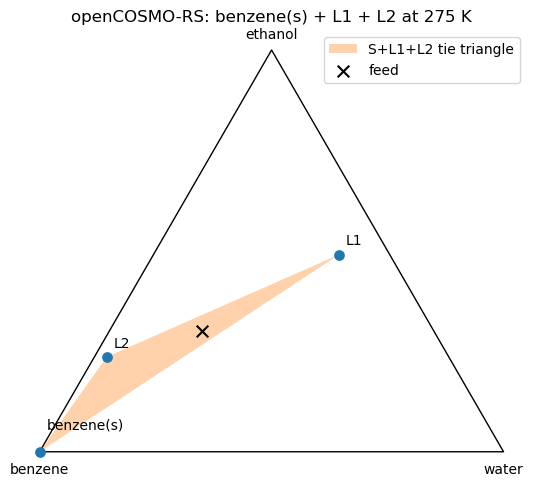

In [4]:
model = build_cosmors_model(parametrization, definitions)
T, P = 275., 101325.
for i in range(3):
    pure = np.eye(3)[i]
    assert abs(model.ln_activity_coefficients(T,pure)[i]) < 1e-5
chart = ReducedChart.build(np.zeros(3), [COMPONENTS[n]['molar_mass_g_mol'] for n in names])
solid = Solid('benzene(s)', [1.,0.,0.], solid_gibbs(T))
feed = np.array([.5,.2,.3])
result = ReducedHELD(model,T,chart,settings,solids=[solid]).flash(feed)
assert result.phase_kinds.count('liquid') == 2 and 'benzene(s)' in result.phase_kinds
print(phase_table(result,names))
print(check_flash(model,T,feed,result,tol=5e-5))
fig,ax = ternary_plot(result,feed,'openCOSMO-RS: benzene(s) + L1 + L2 at 275 K')
plt.show()

## A second feed in the same three-phase region
Only phase amounts should change at fixed T/P. The float backend has finite
numerical precision, so retain honest tolerances and print the residuals.

In [5]:
X = np.asarray(result.mole_fractions)
second_feed = np.array([.25,.4,.35]) @ X
second = ReducedHELD(model,T,chart,settings,solids=[solid]).flash(second_feed)
print('Second feed:',second_feed)
print(phase_table(second,names))
print(check_flash(model,T,second_feed,second,tol=5e-5))
assert second.phase_kinds.count('liquid') == 2 and 'benzene(s)' in second.phase_kinds
first_vertices = np.array(sorted(X,key=lambda x:x[0]))
second_vertices = np.array(sorted(second.mole_fractions,key=lambda x:x[0]))
np.testing.assert_allclose(first_vertices,second_vertices,atol=5e-4)

Second feed: [0.67233032 0.11058533 0.21708435]
[{'phase': 'liquid', 'mole_fraction_of_total': 0.400019057803207, 'mass_fraction_of_total': 0.4276806642806939, 'x_benzene': 0.7377651768417393, 'x_water': 0.02631123544507492, 'x_ethanol': 0.23592358771318594}, {'phase': 'liquid', 'mole_fraction_of_total': 0.24999542332050598, 'mass_fraction_of_total': 0.1485394112925179, 'x_benzene': 0.10890072934711247, 'x_water': 0.4002485168482057, 'x_ethanol': 0.4908507538046819}, {'phase': 'benzene(s)', 'mole_fraction_of_total': 0.34998551887628704, 'mass_fraction_of_total': 0.4237799244267882, 'x_benzene': 1.0, 'x_water': 0.0, 'x_ethanol': 0.0}]
{'species_balance_error_mol': 3.463069699061183e-08, 'liquid_mu_error_over_RT': 1.6170517869174006e-07, 'solid_saturation_error_over_RT': np.float64(7.70782433365258e-08), 'gibbs_reconstruction_error_over_RT': np.float64(1.026034812667831e-11), 'phase_mole_fractions': [0.40001905187194065, 0.24999541961370897, 0.34998551368689096], 'phase_mass_fractions': 

The SAFT and COSMO-RS phase boundaries need not coincide. Compare them at
identical T/P/feed only after each calculation is validated, and report the
parameter set, conformer treatment and solid model. These examples use actual
model evaluations and sourced inputs; they do not establish experimental
SLLE accuracy. To evaluate another real mixture, replace the component records,
conformer inputs and fusion data together. Keep all relevant solid phases and
reference-state conventions consistent.

The saved example assertions apply to default_turbomole and the printed input manifest. A different parameter set can predict a different phase assemblage; inspect it before reusing the same three-phase assertions.